# Wall-Following Robot — EDA, hyperparameter iterations, training

UCI SCITOS G5 wall-following navigation (24 ultrasound sensors).

The test split is frozen first. Hyperparameters are compared on a validation slice of the training rows only. The settings locked in `src/train.py` are applied after that comparison, then models are saved to `model/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataset import encode_labels, features_and_target, load_dataset, stratified_split
from src.metrics import evaluate_classifier
from src.paths import FEATURE_COLS, TARGET_COL
from src.train import train_and_save

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## 1. Load and inspect

In [2]:
df = load_dataset()
print(df.shape)
df.head()

(5456, 25)


,US1,US2,US3,US4,US5,US6,US7,US8,US9,US10,US11,US12,US13,US14,US15,US16,US17,US18,US19,US20,US21,US22,US23,US24,class
0,0.438,0.498,3.625,3.645,5.0,2.918,5.0,2.351,2.332,2.643,1.698,1.687,1.698,1.717,1.744,0.593,0.502,0.493,0.504,0.445,0.431,0.444,0.440,0.429,Slight-Right-Turn
1,0.438,0.498,3.625,3.648,5.0,2.918,5.0,2.637,2.332,2.649,1.695,1.687,1.695,1.720,1.744,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.443,0.429,Slight-Right-Turn
2,0.438,0.498,3.625,3.629,5.0,2.918,5.0,2.637,2.334,2.643,1.696,1.687,1.695,1.717,1.744,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.446,0.429,Slight-Right-Turn
3,0.437,0.501,3.625,3.626,5.0,2.918,5.0,2.353,2.334,2.642,1.730,1.687,1.695,1.717,1.744,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.444,0.429,Slight-Right-Turn
4,0.438,0.498,3.626,3.629,5.0,2.918,5.0,2.640,2.334,2.639,1.696,1.687,1.695,1.717,1.744,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.441,0.429,Slight-Right-Turn


In [3]:
df.info()
display(df.describe().T)
display(df[TARGET_COL].value_counts().to_frame("count"))

<class 'pandas.DataFrame'>
RangeIndex: 5456 entries, 0 to 5455
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   US1     5456 non-null   float64
 1   US2     5456 non-null   float64
 2   US3     5456 non-null   float64
 3   US4     5456 non-null   float64
 4   US5     5456 non-null   float64
 5   US6     5456 non-null   float64
 6   US7     5456 non-null   float64
 7   US8     5456 non-null   float64
 8   US9     5456 non-null   float64
 9   US10    5456 non-null   float64
 10  US11    5456 non-null   float64
 11  US12    5456 non-null   float64
 12  US13    5456 non-null   float64
 13  US14    5456 non-null   float64
 14  US15    5456 non-null   float64
 15  US16    5456 non-null   float64
 16  US17    5456 non-null   float64
 17  US18    5456 non-null   float64
 18  US19    5456 non-null   float64
 19  US20    5456 non-null   float64
 20  US21    5456 non-null   float64
 21  US22    5456 non-null   float64
 22  US23    545

,count,mean,std,min,25%,50%,75%,max
US1,5456.0,1.471617,0.802801,0.400,0.92100,1.3350,1.81400,5.000
US2,5456.0,2.327043,1.410146,0.437,1.36200,1.9045,2.68150,5.025
US3,5456.0,2.489347,1.247435,0.470,1.53875,2.0640,2.73925,5.029
US4,5456.0,2.796501,1.309368,0.833,1.73100,2.4580,4.09350,5.017
US5,5456.0,2.958552,1.339225,1.120,1.77400,2.6670,4.31450,5.000
US6,5456.0,2.893073,1.282575,1.114,1.78575,2.6825,3.83525,5.005
US7,5456.0,3.351113,1.413692,1.122,1.93075,3.2255,5.00000,5.008
US8,5456.0,2.540397,1.111554,0.859,1.61800,2.1720,3.19300,5.087
US9,5456.0,3.125621,1.356965,0.836,1.79975,2.8020,5.00000,5.000
US10,5456.0,2.832386,1.307843,0.810,1.63600,2.6790,3.52625,5.022


,count
class,
Move-Forward,2205
Sharp-Right-Turn,2097
Slight-Right-Turn,826
Slight-Left-Turn,328


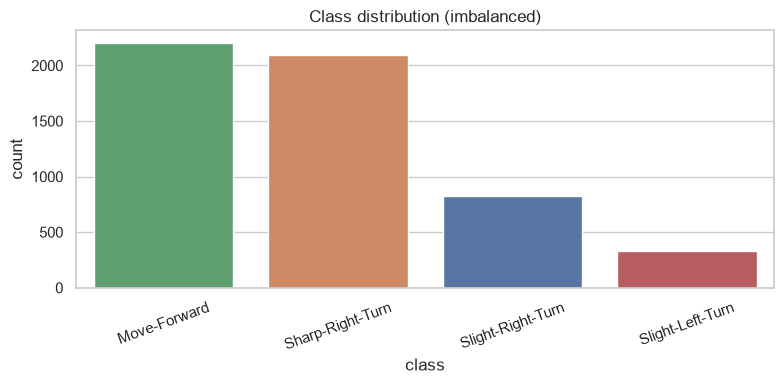

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
order = df[TARGET_COL].value_counts().index
sns.countplot(data=df, x=TARGET_COL, order=order, ax=ax, hue=TARGET_COL, legend=False)
ax.set_title("Class distribution (imbalanced)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

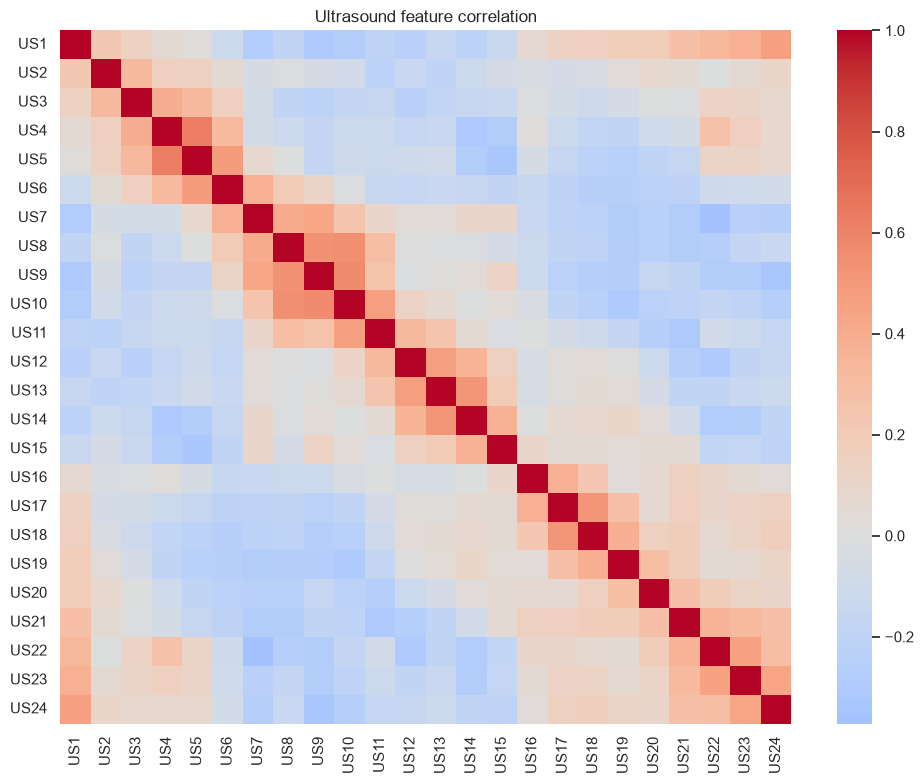

In [5]:
corr = df[FEATURE_COLS].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Ultrasound feature correlation")
plt.tight_layout()
plt.show()

## 2. Freeze the test split, then carve a validation slice

Same stratified 80/20 split as `train_and_save` (`random_state=42`). The held-out test rows are not used while comparing settings. Validation is 20% of the training rows.

In [6]:
train_df, test_df = stratified_split(df, test_size=0.2, random_state=RANDOM_STATE)
fit_df, val_df = stratified_split(train_df, test_size=0.2, random_state=RANDOM_STATE)

X_fit, y_fit = features_and_target(fit_df)
X_val, y_val = features_and_target(val_df)
_encoder, y_fit_enc, y_val_enc = encode_labels(y_fit, y_val)

print(f"fit={len(fit_df)}  val={len(val_df)}  test={len(test_df)} (untouched)")


def validation_table(candidates: list[tuple[dict, Pipeline]]) -> pd.DataFrame:
    rows: list[dict] = []
    for params, pipe in candidates:
        pipe.fit(X_fit, y_fit_enc)
        scores = evaluate_classifier(pipe, X_val, y_val_enc)
        rows.append(
            {
                **params,
                "Accuracy": round(scores["Accuracy"], 4),
                "F1": round(scores["F1"], 4),
                "MCC": round(scores["MCC"], 4),
            }
        )
    table = pd.DataFrame(rows)
    return table.sort_values(["F1", "MCC"], ascending=False).reset_index(drop=True)

fit=3491  val=873  test=1092 (untouched)


## 3. Iterations

Each table is validation F1 / MCC / accuracy. The following section names the setting that `src/train.py` then trains on the full training split.

### 3.1 Logistic regression

`max_iter=2000` is a convergence budget, not a searched hyperparameter. The sweep varies `C` and `class_weight`.

In [7]:
logreg_table = validation_table(
    [
        (
            {"C": c, "class_weight": weight if weight is not None else "none"},
            Pipeline(
                [
                    ("scaler", StandardScaler()),
                    (
                        "clf",
                        LogisticRegression(
                            C=c,
                            class_weight=weight,
                            max_iter=2000,
                            random_state=RANDOM_STATE,
                        ),
                    ),
                ]
            ),
        )
        for c in (0.1, 1.0, 10.0)
        for weight in (None, "balanced")
    ]
)
logreg_table

,C,class_weight,Accuracy,F1,MCC
0,10.0,none,0.7285,0.7287,0.5929
1,1.0,none,0.7262,0.7254,0.5871
2,0.1,none,0.7113,0.7073,0.5606
3,1.0,balanced,0.6850,0.6889,0.5651
4,10.0,balanced,0.6850,0.6884,0.5641
5,0.1,balanced,0.6770,0.6827,0.5519


Unweighted `C=10` leads weighted F1 on this slice. Balanced weights sit a few points lower because they spend accuracy on the rare `Slight-Left-Turn` class. **Locked:** `C=1.0` (sklearn default) and `class_weight="balanced"`.

### 3.2 Decision tree

Depths `4`, `8`, `12`, and unlimited, with and without balanced class weights.

In [8]:
tree_table = validation_table(
    [
        (
            {
                "max_depth": "none" if depth is None else depth,
                "class_weight": weight if weight is not None else "none",
            },
            Pipeline(
                [
                    (
                        "clf",
                        DecisionTreeClassifier(
                            max_depth=depth,
                            class_weight=weight,
                            random_state=RANDOM_STATE,
                        ),
                    )
                ]
            ),
        )
        for depth in (4, 8, 12, None)
        for weight in (None, "balanced")
    ]
)
tree_table

,max_depth,class_weight,Accuracy,F1,MCC
0,8,none,0.9920,0.9920,0.9879
1,12,none,0.9920,0.9920,0.9879
2,none,none,0.9920,0.9920,0.9879
3,12,balanced,0.9897,0.9897,0.9844
4,none,balanced,0.9897,0.9897,0.9844
5,8,balanced,0.9874,0.9874,0.9810
6,4,balanced,0.9485,0.9484,0.9236
7,4,none,0.9061,0.9123,0.8633


Depth 4 is clearly short of the plateau. Depths 8, 12, and unlimited are nearly tied; balanced weights cost well under half a point of F1. **Locked:** `max_depth=12` and `class_weight="balanced"`, a capped tree rather than an unlimited one.

### 3.3 K-nearest neighbors

`n_neighbors` in `{3, 5, 11, 21}` and `weights` in `{uniform, distance}`, after scaling.

In [9]:
knn_table = validation_table(
    [
        (
            {"n_neighbors": k, "weights": weights},
            Pipeline(
                [
                    ("scaler", StandardScaler()),
                    ("clf", KNeighborsClassifier(n_neighbors=k, weights=weights)),
                ]
            ),
        )
        for k in (3, 5, 11, 21)
        for weights in ("uniform", "distance")
    ]
)
knn_table

,n_neighbors,weights,Accuracy,F1,MCC
0,3,distance,0.8763,0.8763,0.8145
1,5,distance,0.8763,0.8762,0.8145
2,3,uniform,0.8625,0.8626,0.7935
3,11,distance,0.8477,0.8478,0.7718
4,5,uniform,0.8396,0.8399,0.7587
5,21,distance,0.8396,0.8396,0.7603
6,11,uniform,0.8076,0.8078,0.7101
7,21,uniform,0.7869,0.7874,0.6796


Distance weighting at `k=3` or `k=5` is the strongest pair. Larger neighborhoods lose F1. **Locked:** `n_neighbors=5` and uniform weights, the simpler of the competitive settings.

### 3.4 Gaussian naive Bayes

Only `var_smoothing` is varied. Neighbouring ultrasound readings are correlated, so this model is expected to stay weak regardless of smoothing.

In [10]:
nb_table = validation_table(
    [
        (
            {"var_smoothing": smoothing},
            Pipeline([("clf", GaussianNB(var_smoothing=smoothing))]),
        )
        for smoothing in (1e-11, 1e-9, 1e-7, 1e-5)
    ]
)
nb_table

,var_smoothing,Accuracy,F1,MCC
0,1.000000e-11,0.5556,0.5591,0.4141
1,1.000000e-09,0.5556,0.5591,0.4141
2,1.000000e-07,0.5556,0.5591,0.4141
3,1.000000e-05,0.5556,0.5591,0.4141


The four smoothing values match on this slice. **Locked:** sklearn's default `var_smoothing=1e-9`.

### 3.5 Support vector machine

`C` in `{0.1, 1, 10}` and `kernel` in `{linear, rbf}`, with `class_weight="balanced"`. Probability calibration is not part of the sweep; the saved pipeline adds `CalibratedClassifierCV` only so the app can report AUC.

In [11]:
svm_table = validation_table(
    [
        (
            {"C": c, "kernel": kernel},
            Pipeline(
                [
                    ("scaler", StandardScaler()),
                    (
                        "clf",
                        SVC(
                            C=c,
                            kernel=kernel,
                            class_weight="balanced",
                            random_state=RANDOM_STATE,
                        ),
                    ),
                ]
            ),
        )
        for c in (0.1, 1.0, 10.0)
        for kernel in ("linear", "rbf")
    ]
)
svm_table

,C,kernel,Accuracy,F1,MCC
0,10.0,rbf,0.9152,0.9155,0.8744
1,1.0,rbf,0.8408,0.8411,0.7715
2,0.1,rbf,0.7388,0.7399,0.6369
3,10.0,linear,0.7125,0.7144,0.5960
4,0.1,linear,0.7068,0.7099,0.5917
5,1.0,linear,0.7045,0.7061,0.5862


RBF beats linear at every `C`. `C=10` is the validation leader; `C=1` is the next RBF setting and still well above the linear models. **Locked:** `kernel="rbf"`, `C=1.0`, `class_weight="balanced"`.

## 4. Locked settings

These are the values `build_models` trains. They are chosen from the tables above, not refit against the test CSV.

| Model | Locked values |
|---|---|
| Logistic regression | `C=1.0`, `class_weight="balanced"`, `max_iter=2000` |
| Decision tree | `max_depth=12`, `class_weight="balanced"` |
| KNN | `n_neighbors=5`, `weights="uniform"`, scaled features |
| Gaussian naive Bayes | `var_smoothing=1e-9` |
| SVM | `kernel="rbf"`, `C=1.0`, `class_weight="balanced"`, then calibration for AUC |

## 5. Train on the full training split and save

`train_and_save` repeats the same outer split, fits the locked pipelines, writes `model/*.joblib`, and exports `data/test_data.csv`.

In [12]:
result = train_and_save(test_size=0.2, random_state=RANDOM_STATE)
print(f"Train size: {result['train_size']}")
print(f"Test size:  {result['test_size']}")
print(f"Classes:    {result['class_names']}")
print(f"Models dir: {result['model_dir']}")
result["table"]

Train size: 4364
Test size:  1092
Classes:    ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']
Models dir: /Users/sreenath/Downloads/bits_wilp/ML_S1-26_AIMLZG565/assignment-2/model


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.6712,0.8777,0.7250,0.6712,0.6782,0.5482
Decision Tree,0.9890,0.9921,0.9891,0.9890,0.9890,0.9834
KNN,0.8599,0.9518,0.8597,0.8599,0.8596,0.7876
Naive Bayes,0.4973,0.7832,0.6196,0.4973,0.5019,0.3630
Support Vector Machine,0.8709,0.9599,0.8836,0.8709,0.8720,0.8139


## 6. Observations on the held-out test set

| Model | Observation |
|---|---|
| Logistic regression | Linear baseline. Balanced weights favour the rare turn class; weighted F1 stays behind the non-linear models. |
| Decision tree | On the depth plateau found above. Best test scores, with the caveat that consecutive robot samples can make a random split look optimistic. |
| KNN | Solid after scaling. Uniform `k=5` is the locked simple setting; distance weighting scored higher on validation. |
| Naive Bayes | Smoothing did not move validation F1. Correlated neighbouring sensors break the independence assumption. |
| SVM | RBF is the kernel the sweep supports. Locked `C=1` is regularised relative to the validation leader `C=10`. |
| **Winner** | Decision tree on the held-out test metrics. |